### Test for a redshft sampler from a gaussian distirbution


In [28]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

In [6]:
z = 0.5
sigma_z = 0.1

### Option 1: Sample directly from a gaussian
We can sample froma  normalized gaussian with mean 'z' and sigma 'sigma_z'. The weights would be implicit in the sampling

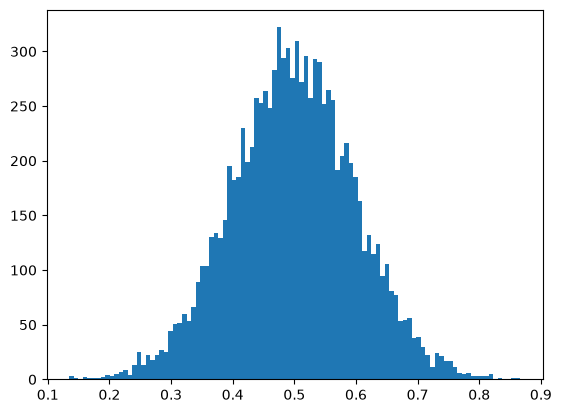

In [25]:

z = 0.5
sigma_z = 0.1
size = 10000

# Direct sampling from a normal distribution
redshift_sample = np.random.normal(z, sigma_z, size=size)

plt.hist(redshift_sample, bins=100)
plt.show()

### Option 2: Samlpe uniformly, weights come from a normalized gaussian

We sample uniformly:
$$
z_i \in [z-3\sigma_z, z+3\sigma_z]
$$


(Keeping in mind that the minimum should not be below 0).Then, we obtain a weight from the gaussian distribution: 
$$
\omega_i = Gauss(z_i, \mu=z, \sigma=\sigma_z)
$$

And compute a weighted average of the classification vector: 

$$
\vec X^{avg}(z) = \frac{\sum \omega_i \vec X(z_i)}{\sum \omega_i}
$$

In [ ]:
# size = 10000
# z_dist = np.random.normal(z, sigma_z, size=size)
# pdf_z = z_dist / np.sum(z_dist)

# z_grid = np.linspace(z - 5 * sigma_z, z+ 5 * sigma_z, size)
# redshift_sample = np.random.choice(z_grid, p=pdf_z, size=size)


In [39]:
z = 0.5
sigma_z = 0.1
sample_size = 5

weight = norm.pdf(0.1, loc=z, scale=sigma_z)

z_sample = np.linspace(max(z - 3 *sigma_z, 0), z + 3 *sigma_z, sample_size)
for z_i in z_sample: 
    print('z_i: ', z_i, ' | w_i: ', norm.pdf(z_i, loc=z, scale=sigma_z))

z_i:  0.19999999999999996  | w_i:  0.04431848411938
z_i:  0.35  | w_i:  1.2951759566589167
z_i:  0.5  | w_i:  3.989422804014327
z_i:  0.65  | w_i:  1.2951759566589167
z_i:  0.8  | w_i:  0.04431848411938


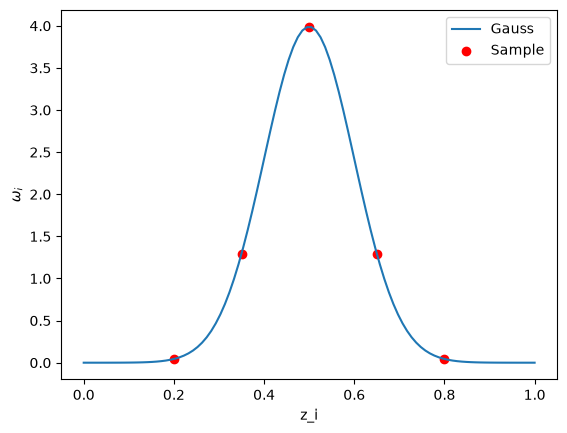

In [45]:
#gaussian
x = np.linspace(0, 1, 100)
y = norm.pdf(x, loc=z, scale=sigma_z)
plt.plot(x, y, label='Gauss')
plt.scatter(z_sample, norm.pdf(z_sample, loc=z, scale=sigma_z), c='red', label='Sample')
plt.xlabel('z_i')
plt.ylabel(r'$\omega_i$')
plt.legend()
plt.show()

## Averaging different catalog redshifts

When we have the scenario of more than one photometric or spcetroscopic redshift from a catalogue: 
1. $z = 0.5 \pm 0.1$
2. $z = 0.6 \pm 0.2$
...
Then we need a way to average them or choose a preference

### Option 1: ranking order
We can have a custom order where we choose the most reliable catalogues: 
1. Spectroscopic: 
    - NED
2. Photometric: 
    - LS
    - ...

Then we simply choose the highest ranking catalogue

### Option 2: Simple average and propagating the uncertainties

We can take the average of all catalogues assuming equal weight between them: 

$$
\overline z = \frac{1}{N_z} \sum^{N_z}_i z_i
$$

And then propagate the gaussian error: 

$$
\overline \sigma_z = \frac{\sqrt{\sigma_1^2 + \sigma_2^2 + ... + \sigma_N^2}}{N_z} = \frac{1}{N_z}\sqrt{\sum_i^{N_z}\sigma_i^2}
$$


### Option 3: Weighted average and error propagation

We can add a reliablity criteria based on the **size** of the error, assigning a higher weight to measurements with lower errors:
$$
\omega_i = \frac{1}{\sigma_i^2}
$$

Then we can optain a weighted average

$$
\overline z = \frac{\sum_i^{N_z}\omega_i z_i}{\sum_i^{N_z}\omega_i } = \frac{\sum_i^{N_z}\frac{z_i}{\sigma_i^2}}{\sum_i^{N_z}\frac{1}{\sigma_z^2}}
$$

And then the error propagation will also take into account the weight: 

$$
\overline \sigma_z = \frac{1}{\sqrt{\sum_i^{N_z} \omega_i}}
$$

### Option 4: Weighted average with custom weights: 

Same as #3, but instead of using the error size as weight we use custom values for the catalogues we find useful. For example: 

$$
\vec \omega = [\text{NED} = 10, \text{LS} = 1, \text{other} = 0.1]
$$